# MER as an dlm

In [1]:
# necessary imports
import pandas as pd
import numpy as np
import pydlm
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from prettytable import PrettyTable

In [2]:
# load the dataset
df = pd.read_csv(r"C:\Users\karol\Desktop\Dissertação\LAMIR\base_completa.csv", sep=';')
df.head()

,frameTime,F0final_sma_stddev,F0final_sma_amean,voicingFinalUnclipped_sma_stddev,voicingFinalUnclipped_sma_amean,jitterLocal_sma_stddev,jitterLocal_sma_amean,jitterDDP_sma_stddev,jitterDDP_sma_amean,shimmerLocal_sma_stddev,...,pcm_fftMag_mfcc_sma_de[11]_amean,pcm_fftMag_mfcc_sma_de[12]_stddev,pcm_fftMag_mfcc_sma_de[12]_amean,pcm_fftMag_mfcc_sma_de[13]_stddev,pcm_fftMag_mfcc_sma_de[13]_amean,pcm_fftMag_mfcc_sma_de[14]_stddev,pcm_fftMag_mfcc_sma_de[14]_amean,Arousal,Valence,file
0,15.0,92.32464,231.3143,0.040914,0.765672,0.113629,0.095577,0.169125,0.125609,0.072958,...,0.048962,1.801655,-0.038486,1.782184,-0.108969,1.737632,-0.288386,0.403,0.230,1206
1,15.5,93.75675,182.7388,0.024632,0.755606,0.138227,0.125566,0.189668,0.172306,0.078672,...,-0.072746,2.097589,-0.082500,2.125764,-0.099135,1.642303,-0.073503,0.398,0.234,1206
2,16.0,104.79450,160.4234,0.031243,0.743381,0.128711,0.116316,0.139655,0.110124,0.073977,...,-0.029705,2.066815,0.114558,1.952615,0.141956,1.526618,0.009980,0.402,0.233,1206
3,16.5,127.15860,171.9173,0.025678,0.739337,0.096494,0.078068,0.061657,0.047470,0.091804,...,0.079123,1.923910,0.008574,2.116269,0.014956,1.444731,0.114898,0.401,0.233,1206
4,17.0,106.40380,229.6989,0.062971,0.798236,0.072736,0.058147,0.044665,0.036389,0.068682,...,0.083749,2.005052,-0.009383,2.163749,-0.231284,1.613237,-0.013179,0.407,0.243,1206


Let $\alpha_t$ as Arousal and $\upsilon_t$ as Valence

**obs.:** `dlm` only supports one dimensional time series [see here](https://pydlm.github.io/pydlm_user_guide.html#modeling)

In [3]:
# testing for the first file
# filter the dataset for file 2 and drop unnecessary columns
features_1 = df.query('file == 2').drop(columns=['frameTime', 'Arousal', 'Valence', 'file'])
features_1.head()

,F0final_sma_stddev,F0final_sma_amean,voicingFinalUnclipped_sma_stddev,voicingFinalUnclipped_sma_amean,jitterLocal_sma_stddev,jitterLocal_sma_amean,jitterDDP_sma_stddev,jitterDDP_sma_amean,shimmerLocal_sma_stddev,shimmerLocal_sma_amean,...,pcm_fftMag_mfcc_sma_de[10]_stddev,pcm_fftMag_mfcc_sma_de[10]_amean,pcm_fftMag_mfcc_sma_de[11]_stddev,pcm_fftMag_mfcc_sma_de[11]_amean,pcm_fftMag_mfcc_sma_de[12]_stddev,pcm_fftMag_mfcc_sma_de[12]_amean,pcm_fftMag_mfcc_sma_de[13]_stddev,pcm_fftMag_mfcc_sma_de[13]_amean,pcm_fftMag_mfcc_sma_de[14]_stddev,pcm_fftMag_mfcc_sma_de[14]_amean
58420,12.179310,101.6302,0.028607,0.759366,0.153100,0.141526,0.082871,0.102391,0.190714,0.297502,...,2.113171,-0.045443,2.246814,-0.175230,2.488252,-0.177010,1.845097,0.062042,2.156926,0.070399
58421,9.061675,108.4007,0.023301,0.782306,0.125588,0.054276,0.072678,0.056975,0.157019,0.190125,...,2.080907,0.001877,2.480643,0.232135,2.331740,-0.158096,2.049178,0.016943,1.694531,0.036801
58422,2.424723,111.3184,0.025118,0.791416,0.024865,0.023444,0.035991,0.035839,0.087490,0.152249,...,2.344492,-0.095686,2.984664,0.216907,2.957226,0.028751,2.177865,-0.120895,1.762214,0.030089
58423,10.090170,108.1190,0.024484,0.790459,0.111933,0.068022,0.140163,0.084378,0.092591,0.151124,...,2.685361,-0.134019,2.430664,-0.125082,2.765290,-0.113778,2.214839,0.109757,1.669868,-0.088037
58424,9.906472,106.0409,0.022463,0.785395,0.110868,0.068772,0.139967,0.085360,0.098301,0.156241,...,2.256249,-0.148475,1.796319,-0.251045,1.981488,-0.064730,2.544847,0.110850,1.621264,0.013263


In [4]:
# create a pipeline for PCA with standard scaling
# fit the pipeline to the features and transform them
pca_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components = 10, random_state=42))
])
features_1_PCA = pca_pipeline.fit_transform(features_1)
np.sum(pca_pipeline.named_steps['pca'].explained_variance_ratio_)

np.float64(0.7236642429596829)

In [5]:
# create a dataframe with the PCA components and the original feature names
most_important = pd.DataFrame(pca_pipeline.named_steps['pca'].components_,columns=features_1.columns)
most_important.max().idxmax()

'voicingFinalUnclipped_sma_de_amean'

In [6]:
## Adding a column of ones to the PCA features for bias term in regression models
features_1_PCA = np.hstack((features_1_PCA, np.ones((len(features_1_PCA), 1)))) 
a_1 = df.query('file == 2')['Arousal']
v_1 = df.query('file == 2')['Valence']

In [7]:
## Fitting the dynamic linear models for Arousal and Valence using the PCA features
dlm_a = pydlm.dlm(a_1) + pydlm.dynamic(features = features_1_PCA, discount = 0.5)
dlm_v = pydlm.dlm(v_1) + pydlm.dynamic(features= features_1_PCA, discount=0.5)
dlm_a.fit()
dlm_v.fit()
dlm_a.turnOff('confidence')
dlm_v.turnOff('confidence')

INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...
INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.
INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...
INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.


<Figure size 1200x500 with 0 Axes>

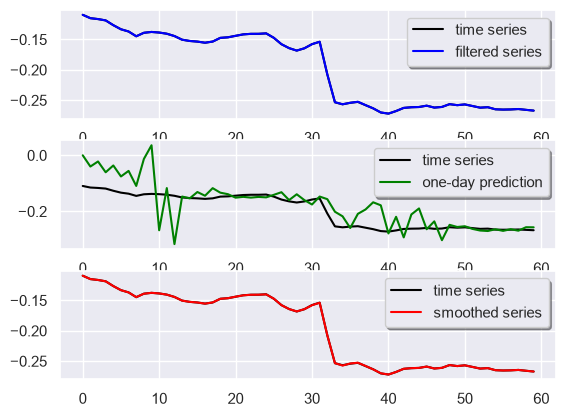

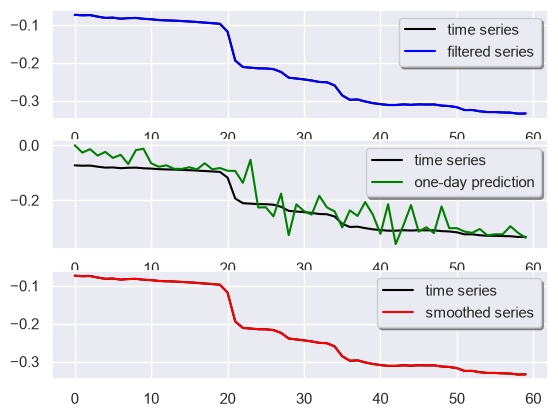

<Figure size 640x480 with 0 Axes>

In [8]:
# Define o tamanho total da figura
plt.figure(figsize=(12, 5))

# Cria o primeiro espaço (1 linha, 2 colunas, gráfico 1)
dlm_a.plot()

# Cria o segundo espaço (1 linha, 2 colunas, gráfico 2)
dlm_v.plot()

# Ajusta os espaçamentos e exibe
plt.tight_layout()
plt.show()

In [9]:
dados = {
    "Modelo": ["Arousal", "Valence"],
    "MSE": [np.round(dlm_a.getMSE(), 5), np.round(dlm_v.getMSE(), 5)]
}
# Converte para DataFrame e exibe
tabela_df = pd.DataFrame(dados)
display(tabela_df)

,Modelo,MSE
0,Arousal,0.00318
1,Valence,0.00234


# 70/30 split of the same song

idea: For each song, the code will try to predict the final 30% of the song based on the initial 70%.

In [10]:
results_mse = []

for music in df['file'].unique():

    df_i = df.query('file == @music')

    features_i = df_i.drop(columns=['frameTime', 'Arousal', 'Valence', 'file'])
    a_i = df_i['Arousal'].to_numpy()
    v_i = df_i['Valence'].to_numpy()

    n = len(df_i)
    n_fit = int(0.7 * n)
    n_forecast = n - n_fit

    # Guarda de segurança: música curta demais pra dar split coerente
    if n_fit <= 10 or n_forecast < 1:
        print(f'Pulando música {music}: poucos frames ({n})')
        continue

    # PCA ajustado só nos primeiros 70% (fit), aplicado na música toda
    pca_pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=10, random_state=42))
    ])
    pca_pipeline.fit(features_i.iloc[:n_fit])
    features_i_PCA = pca_pipeline.transform(features_i)
    features_i_PCA = np.hstack((features_i_PCA, np.ones((n, 1))))  # intercepto

    features_fit = features_i_PCA[:n_fit].tolist()
    features_forecast = features_i_PCA[n_fit:].tolist()

    for nome_resp, y in [('Arousal', a_i), ('Valence', v_i)]:

        modelo = pydlm.dlm(y[:n_fit].tolist()) + pydlm.dynamic(
            features=features_fit,
            name='dynamic',
            discount=0.5
        )
        modelo.fit()

        previsao, _ = modelo.predictN(
            N=n_forecast,
            featureDict={'dynamic': features_forecast}
        )

        y_true = y[n_fit:]
        mse = np.mean((np.array(previsao) - y_true) ** 2)

        results_mse.append({
            'file': music,
            'resposta': nome_resp,
            'n_frames': n,
            'n_fit': n_fit,
            'n_forecast': n_forecast,
            'mse': mse
        })

df_mse = pd.DataFrame(results_mse)

INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...
INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.
INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...
INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.
INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...
INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.
INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...
INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.
INFO:pydlm:Initializing models...
INFO:pydlm:Initialization fini

In [11]:
df_mse

,file,resposta,n_frames,n_fit,n_forecast,mse
0,1206,Arousal,58,40,18,0.000397
1,1206,Valence,58,40,18,0.000467
2,1207,Arousal,58,40,18,0.001665
3,1207,Valence,58,40,18,0.000241
4,1208,Arousal,58,40,18,0.000657
...,...,...,...,...,...,...
3599,1203,Valence,58,40,18,0.001163
3600,1204,Arousal,58,40,18,0.000330
3601,1204,Valence,58,40,18,0.000675
3602,1205,Arousal,58,40,18,0.000195


In [12]:
df_mse_wide = df_mse.pivot(index='file', columns='resposta', values='mse')
df_mse_wide.head()

resposta,Arousal,Valence
file,,
2,0.003960,0.003420
3,0.004967,0.000422
4,0.005129,0.018182
5,0.000231,0.000035
7,0.000052,0.003009


In [13]:
# Group the results by 'resposta' and calculate mean, median, and std of MSE
df_mse.groupby('resposta')['mse'].agg(['min',('q25', lambda x: x.quantile(0.25)), 'median', ('q75', lambda x: x.quantile(0.75)), ('q99', lambda x: x.quantile(0.99)), 'max', 'mean', 'std'])

,min,q25,median,q75,q99,max,mean,std
resposta,,,,,,,,
Arousal,0.000004,0.000464,0.001348,0.004377,0.130954,9.620000,0.015647,0.243711
Valence,0.000002,0.000398,0.001151,0.003414,0.112086,16.211334,0.017178,0.387824


predicted vs. true

In [22]:
def plot_previsao_musica(df, musica, discount=0.5, n_components=10, frac_fit=0.7, ylim=(-1, 1),
                          figsize=(3.4, 3.0), fontsize=8):

    df_i = df.query('file == @musica')

    features_i = df_i.drop(columns=['frameTime', 'Arousal', 'Valence', 'file'])
    a_i = df_i['Arousal'].to_numpy()
    v_i = df_i['Valence'].to_numpy()

    n = len(df_i)
    n_fit = int(frac_fit * n)
    n_forecast = n - n_fit

    if n_fit <= n_components or n_forecast < 1:
        raise ValueError(f'Música {musica} tem poucos frames ({n}) para esse split.')

    pca_pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=n_components, random_state=42))
    ])
    pca_pipeline.fit(features_i.iloc[:n_fit])
    features_i_PCA = pca_pipeline.transform(features_i)
    features_i_PCA = np.hstack((features_i_PCA, np.ones((n, 1))))

    features_fit = features_i_PCA[:n_fit].tolist()
    features_forecast = features_i_PCA[n_fit:].tolist()

    plt.rcParams.update({'font.size': fontsize})
    fig, axes = plt.subplots(2, 1, figsize=figsize, sharex=True)
    resultados = {}

    for ax, nome_resp, y in zip(axes, ['Arousal', 'Valence'], [a_i, v_i]):

        modelo = pydlm.dlm(y[:n_fit].tolist()) + pydlm.dynamic(
            features=features_fit, name='dynamic', discount=discount
        )
        modelo.fit()

        previsao, var = modelo.predictN(
            N=n_forecast, featureDict={'dynamic': features_forecast}
        )
        previsao = np.array(previsao)
        std = np.sqrt(np.array(var))

        y_true_forecast = y[n_fit:]
        mse = np.mean((previsao - y_true_forecast) ** 2)
        resultados[nome_resp] = mse

        eixo_x = np.arange(n_forecast)

        ax.plot(eixo_x, y_true_forecast, color='black', label='True', linewidth=0.8)
        ax.plot(eixo_x, previsao, color='tab:red', linestyle='--', label='Predicted', linewidth=0.8)
#        ax.fill_between(
#            eixo_x, previsao - 1.96 * std, previsao + 1.96 * std,
#            color='tab:red', alpha=0.15, label='95% CI'
#        )
        ax.set_ylim(ylim)
        ax.set_ylabel(nome_resp, fontsize=fontsize)
        ax.tick_params(labelsize=fontsize - 1)
        ax.legend(loc='lower right', fontsize=fontsize - 2, frameon=False)

    axes[-1].set_xlabel('Prediction', fontsize=fontsize)
    fig.suptitle(f'Music: {musica}  |  MSE Arousal={resultados["Arousal"]:.4f}  '
                f'MSE Valence={resultados["Valence"]:.4f}', fontsize=fontsize)
    plt.tight_layout()
    fig.savefig(f'musica_{musica}.pdf', bbox_inches='tight')
    plt.show()

    return resultados

INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...
INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.
INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...
INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.


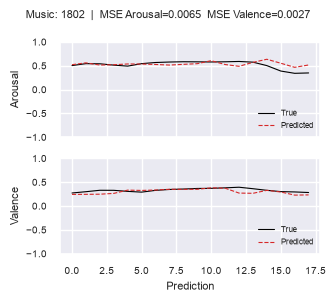

{'Arousal': np.float64(0.006473711795879798),
 'Valence': np.float64(0.0027115356270815227)}

In [23]:
# música específica
plot_previsao_musica(df, musica=1802)

INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...
INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.
INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...
INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.


[   9.34160154  411.34739883 1003.55156635 1323.58462076 1438.08403925
 1461.22425009 2673.62371898 2859.26589535 3106.83183382 3293.87711718
 2477.84765011 1931.01465691 1799.04574618 1862.78307494 1695.23534889
 2000.01105139 2256.55196253 2182.21980092]
[   9.34149015  411.34249418 1003.53960064 1323.56883917 1438.06689244
 1461.20682737 2673.59184038 2859.23180327 3106.79478992 3293.83784307
 2477.81810583 1930.99163271 1799.0242955  1862.76086429 1695.21513597
 1999.98720453 2256.52505683 2182.19378151]


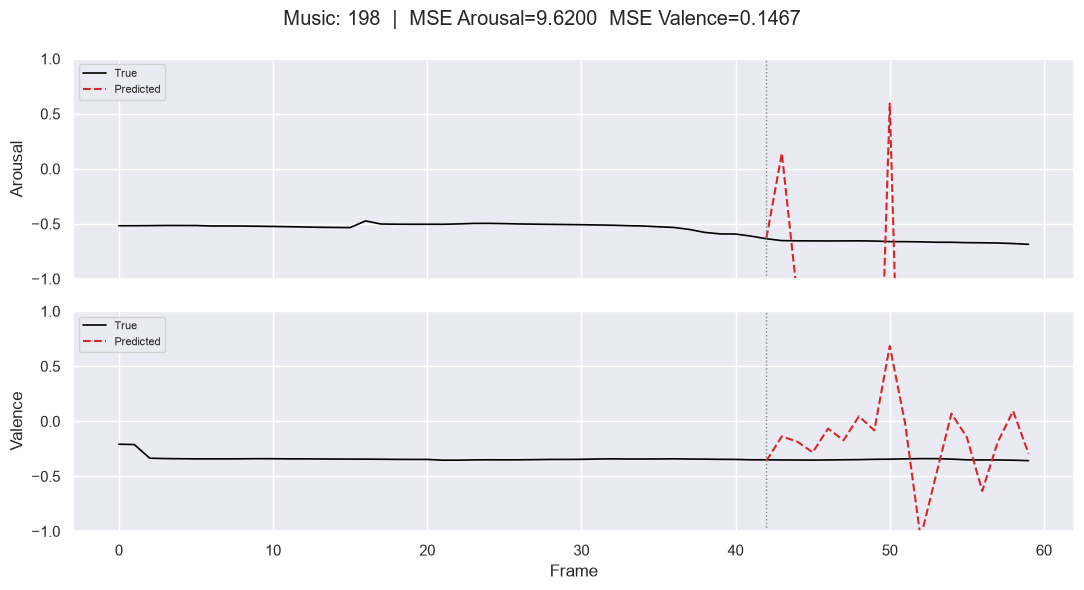

{'Arousal': np.float64(9.61999983139514),
 'Valence': np.float64(0.14668425787208)}

In [24]:
plot_previsao_musica(df, musica=198, ylim=(-1, 1))

#### Quais features originais mais influenciam Arousal/Valence, considerando que o dlm estima coeficientes sobre os componentes principais, não sobre as features originais?

In [18]:
def importancia_features_musica(df, musica, discount=0.5, n_components=10):

    df_i = df.query('file == @musica')
    features_i = df_i.drop(columns=['frameTime', 'Arousal', 'Valence', 'file'])
    nomes_features = features_i.columns

    pca_pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=n_components, random_state=42))
    ])
    features_i_PCA = pca_pipeline.fit_transform(features_i)
    features_i_PCA = np.hstack((features_i_PCA, np.ones((len(df_i), 1))))  # intercepto por último

    loadings = pca_pipeline.named_steps['pca'].components_  # shape (n_components, n_features_originais)

    resultados = {}
    for nome_resp, y in [('Arousal', df_i['Arousal'].to_numpy()), ('Valence', df_i['Valence'].to_numpy())]:

        modelo = pydlm.dlm(y.tolist()) + pydlm.dynamic(
            features=features_i_PCA.tolist(), name='dynamic', discount=discount
        )
        modelo.fit()

        estados = np.array(modelo.getLatentState(filterType='backwardSmoother', name='dynamic'))
        coef_pcs = estados[:, :n_components]  # descarta a coluna do intercepto

        # coeficiente efetivo por feature original, em cada frame
        coef_features_original = coef_pcs @ loadings  # (n_frames, n_features_originais)

        # resumo: magnitude média absoluta ao longo da música
        importancia = pd.Series(
            np.abs(coef_features_original).mean(axis=0),
            index=nomes_features
        ).sort_values(ascending=False)

        resultados[nome_resp] = importancia

    return resultados

In [19]:
imp = importancia_features_musica(df, musica=2)
imp['Arousal'].head(5)   # top 5 features que mais influenciam Arousal nessa música
imp['Valence'].head(5)   # top 5 features que mais influenciam Valence nessa música

INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...


INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.
INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...
INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.


pcm_fftMag_mfcc_sma[3]_amean           0.001352
pcm_fftMag_mfcc_sma[5]_amean           0.001282
voicingFinalUnclipped_sma_de_stddev    0.001281
pcm_fftMag_mfcc_sma[6]_amean           0.001174
pcm_fftMag_mfcc_sma[9]_amean           0.001112
dtype: float64

#### Quais features aparecem com mais frequência no top-5 de cada música (após aplicação do PCA e DLM)

In [20]:
def agregar_importancia_features(df, discount=0.5, n_components=10, top_n=5, verbose=True):

    registros = []

    for musica in df['file'].unique():

        df_i = df.query('file == @musica')
        if len(df_i) <= n_components:
            if verbose:
                print(f'Pulando música {musica}: poucos frames ({len(df_i)})')
            continue

        try:
            resultado = importancia_features_musica(
                df, musica=musica, discount=discount, n_components=n_components
            )
        except Exception as e:
            if verbose:
                print(f'Falhou na música {musica}: {e}')
            continue

        for nome_resp, importancia in resultado.items():
            for feature, valor in importancia.items():
                registros.append({
                    'file': musica,
                    'resposta': nome_resp,
                    'feature': feature,
                    'importancia': valor
                })

    df_importancia = pd.DataFrame(registros)

    # Visão 1: magnitude média do coeficiente, entre todas as músicas
    resumo = (
        df_importancia
        .groupby(['resposta', 'feature'])['importancia']
        .agg(['mean', 'median', 'std', 'count'])
        .sort_values(['resposta', 'mean'], ascending=[True, False])
    )

    # Visão 2: em quantas músicas a feature aparece no top-N
    def top_n_por_musica(grupo):
        return grupo.nlargest(top_n, 'importancia')

    top_por_musica = (
        df_importancia
        .sort_values('importancia', ascending=False)
        .groupby(['resposta', 'file'])
        .head(top_n)
    )

    total_musicas = df_importancia['file'].nunique()

    frequencia_top_n = (
        top_por_musica
        .groupby(['resposta', 'feature'])
        .size()
        .rename('n_musicas_no_top')
        .reset_index()
    )
    frequencia_top_n['pct_musicas'] = 100 * frequencia_top_n['n_musicas_no_top'] / total_musicas
    frequencia_top_n = frequencia_top_n.sort_values(
        ['resposta', 'n_musicas_no_top'], ascending=[True, False]
    )

    return df_importancia, resumo, frequencia_top_n

In [21]:
df_importancia, resumo, frequencia_top_n = agregar_importancia_features(df, top_n=5)
resumo.loc['Arousal'].head(10) 

INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...
INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.
INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...
INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.
INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...
INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.
INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...
INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.
INFO:pydlm:Initializing models...
INFO:pydlm:Initialization fini

,mean,median,std,count
feature,,,,
voicingFinalUnclipped_sma_de_stddev,0.001252,0.001091,0.000739,1802
shimmerLocal_sma_de_stddev,0.001222,0.001071,0.000706,1802
jitterLocal_sma_de_stddev,0.001186,0.001040,0.000712,1802
jitterDDP_sma_de_stddev,0.001175,0.001021,0.000727,1802
logHNR_sma_de_stddev,0.001110,0.000940,0.000716,1802
pcm_fftMag_mfcc_sma[7]_amean,0.001079,0.000914,0.000707,1802
F0final_sma_de_stddev,0.001077,0.000933,0.000645,1802
pcm_fftMag_mfcc_sma[3]_amean,0.001075,0.000939,0.000669,1802
pcm_fftMag_mfcc_sma[6]_amean,0.001072,0.000906,0.000712,1802


In [22]:
frequencia_top_n.query('resposta == "Arousal"').head(10)   # top 10 por frequência no top-5

,resposta,feature,n_musicas_no_top,pct_musicas
257,Arousal,voicingFinalUnclipped_sma_de_stddev,317,17.591565
253,Arousal,shimmerLocal_sma_de_stddev,265,14.705882
117,Arousal,jitterDDP_sma_de_stddev,235,13.041065
121,Arousal,jitterLocal_sma_de_stddev,225,12.486127
125,Arousal,logHNR_sma_de_stddev,150,8.324084
2,Arousal,F0final_sma_de_stddev,124,6.881243
145,Arousal,pcm_fftMag_mfcc_sma[13]_amean,124,6.881243
159,Arousal,pcm_fftMag_mfcc_sma[6]_amean,123,6.825749
141,Arousal,pcm_fftMag_mfcc_sma[11]_amean,121,6.714761
143,Arousal,pcm_fftMag_mfcc_sma[12]_amean,121,6.714761


In [23]:
frequencia_top_n.query('resposta == "Valence"').head(10)   # top 10 por frequência no top-5

,resposta,feature,n_musicas_no_top,pct_musicas
514,Valence,voicingFinalUnclipped_sma_de_stddev,298,16.537181
510,Valence,shimmerLocal_sma_de_stddev,270,14.983352
378,Valence,jitterLocal_sma_de_stddev,225,12.486127
374,Valence,jitterDDP_sma_de_stddev,222,12.319645
382,Valence,logHNR_sma_de_stddev,155,8.601554
261,Valence,F0final_sma_de_stddev,130,7.214206
402,Valence,pcm_fftMag_mfcc_sma[13]_amean,125,6.936737
398,Valence,pcm_fftMag_mfcc_sma[11]_amean,124,6.881243
400,Valence,pcm_fftMag_mfcc_sma[12]_amean,122,6.770255
418,Valence,pcm_fftMag_mfcc_sma[7]_amean,120,6.659267


#### Quais são as features que mais aparecem após aplicar PCA e DLM ?

In [24]:
def agregar_importancia_features(df, discount=0.5, n_components=10, verbose=True):

    registros = []

    for musica in df['file'].unique():

        df_i = df.query('file == @musica')
        if len(df_i) <= n_components:
            if verbose:
                print(f'Pulando música {musica}: poucos frames ({len(df_i)})')
            continue

        try:
            resultado = importancia_features_musica(
                df, musica=musica, discount=discount, n_components=n_components
            )
        except Exception as e:
            if verbose:
                print(f'Falhou na música {musica}: {e}')
            continue

        for nome_resp, importancia in resultado.items():
            for feature, valor in importancia.items():
                registros.append({
                    'file': musica,
                    'resposta': nome_resp,
                    'feature': feature,
                    'importancia': valor
                })

    df_importancia = pd.DataFrame(registros)

    # rank de cada feature DENTRO de cada música (1 = mais importante naquela música)
    df_importancia['rank'] = (
        df_importancia
        .groupby(['resposta', 'file'])['importancia']
        .rank(ascending=False, method='average')
    )

    resumo = (
        df_importancia
        .groupby(['resposta', 'feature'])['importancia']
        .agg(['mean', 'median', 'std'])
        .sort_values(['resposta', 'mean'], ascending=[True, False])
    )

    resumo_rank = (
        df_importancia
        .groupby(['resposta', 'feature'])['rank']
        .agg(['mean', 'median', 'std'])
        .rename(columns={'mean': 'rank_medio', 'median': 'rank_mediano', 'std': 'rank_std'})
        .sort_values(['resposta', 'rank_medio'])   # menor rank médio = mais importante
    )

    return df_importancia, resumo, resumo_rank

In [25]:
df_importancia, resumo, resumo_rank = agregar_importancia_features(df)

resumo_rank.loc['Arousal'].head(5)   # top 5 por rank médio
resumo_rank.loc['Valence'].head(5)

INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...
INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.
INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...
INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.
INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...
INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.
INFO:pydlm:Initializing models...
INFO:pydlm:Initialization finished.
INFO:pydlm:Starting forward filtering...
INFO:pydlm:Forward filtering completed.
INFO:pydlm:Starting backward smoothing...
INFO:pydlm:Backward smoothing completed.
INFO:pydlm:Initializing models...
INFO:pydlm:Initialization fini

,rank_medio,rank_mediano,rank_std
feature,,,
voicingFinalUnclipped_sma_de_stddev,57.835183,34.0,60.832262
shimmerLocal_sma_de_stddev,61.865150,38.0,63.315556
jitterLocal_sma_de_stddev,63.402886,41.0,61.875991
jitterDDP_sma_de_stddev,65.570200,45.0,62.333244
F0final_sma_de_stddev,77.091565,60.0,64.204472


In [28]:
resumo_rank.loc['Arousal'].head(5)   # top 5 por rank médio

,rank_medio,rank_mediano,rank_std
feature,,,
voicingFinalUnclipped_sma_de_stddev,57.458935,34.0,60.633109
shimmerLocal_sma_de_stddev,59.373474,36.0,61.176734
jitterLocal_sma_de_stddev,63.733629,42.0,62.421354
jitterDDP_sma_de_stddev,66.560766,45.0,63.671651
pcm_fftMag_mfcc_sma[3]_amean,77.693674,61.0,64.009026


In [29]:
resumo_rank.loc['Valence'].head(5)

,rank_medio,rank_mediano,rank_std
feature,,,
voicingFinalUnclipped_sma_de_stddev,57.835183,34.0,60.832262
shimmerLocal_sma_de_stddev,61.865150,38.0,63.315556
jitterLocal_sma_de_stddev,63.402886,41.0,61.875991
jitterDDP_sma_de_stddev,65.570200,45.0,62.333244
F0final_sma_de_stddev,77.091565,60.0,64.204472


In [26]:
resumo_rank.loc['Arousal'].tail(10)

# voicingFinalUnclipped_sma_de_stddev, em média, está na posição 57 (relevância)

,rank_medio,rank_mediano,rank_std
feature,,,
audSpec_Rfilt_sma_de[12]_amean,182.269700,196.0,61.517462
audSpec_Rfilt_sma_de[14]_amean,182.839623,201.0,62.864213
audSpec_Rfilt_sma_de[13]_amean,183.259711,201.0,63.389511
audSpec_Rfilt_sma_de[19]_amean,185.628191,202.0,61.661463
audSpec_Rfilt_sma_de[18]_amean,185.886792,201.0,61.007463
audSpec_Rfilt_sma_de[16]_amean,186.516093,202.5,61.109917
audSpec_Rfilt_sma_de[15]_amean,186.877358,205.0,61.934921
audSpec_Rfilt_sma_de[17]_amean,187.495560,205.5,61.135319
audspecRasta_lengthL1norm_sma_de_amean,191.639290,210.0,61.070978


In [27]:
resumo_rank.loc['Valence'].tail(10)

,rank_medio,rank_mediano,rank_std
feature,,,
audSpec_Rfilt_sma_de[14]_amean,183.558269,202.0,62.238577
audSpec_Rfilt_sma_de[12]_amean,184.417869,200.0,61.301706
audSpec_Rfilt_sma_de[13]_amean,184.596004,201.5,62.765836
audSpec_Rfilt_sma_de[19]_amean,185.034406,199.0,59.928997
audSpec_Rfilt_sma_de[15]_amean,185.879578,203.0,61.847921
audSpec_Rfilt_sma_de[18]_amean,185.922309,200.0,59.945251
audSpec_Rfilt_sma_de[16]_amean,186.567703,201.0,60.488196
audSpec_Rfilt_sma_de[17]_amean,188.237514,204.0,60.254247
audspecRasta_lengthL1norm_sma_de_amean,191.860155,210.0,60.385476
